![imagen](../img/seaborn.png)


# Análisis exploratorio de datos (EDA) con Seaborn
Entender cómo se hacen las gráficas en Python está muy bien, pero lo importante es saber cuándo usarlas. En este notebook no se pretende explicar todos los tipos de gráficas que hay (histogramas, scatter plots, heatmaps...), en primer lugar porque es imposible abarcarlo todo, y en segundo lugar porque hay que ir un paso atrás antes de elegir la gráfica, ya que tenemos que comprender de qué tipo son los datos y qué es lo que estamos buscando con cada gráfica.

Por tanto, primero tendremos que identificar el tipo de los datos y cuántas variables vamos a representar:
- Una variable numérica
- Una variable categórica
- Dos variables numéricas
- Tres o más variables numéricas
- Dos variables categóricas
- Variables numéricas y categóricas

Teniendo claro esto, junto con un buen catálogo de gráficas, lo tendremos mucho más fácil.

https://www.data-to-viz.com/

In [1]:
# Importamos todos los paquetes que vayamos a necesitar
from sklearn.datasets import load_iris
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Algunas configuraciones de los paquetes
pd.set_option("display.max_rows", 500) # Cuántas filas de los DataFrames nos "escupe" pandas en el Notebook
sns.set_theme(color_codes=True)

In [2]:
# Cargamos las features en un DataFrame:
iris = load_iris()
iris_df = pd.DataFrame(iris["data"], columns=iris["feature_names"])

# Y añadimos la columna de especies:
iris_df["target"] = iris["target_names"][iris["target"]]

# Cargamos también el dataset del titanic
titanic_df = pd.read_csv("../data/titanic.csv")

# Cargamos los datos del supermarket sales
market_df = pd.read_csv("../data/supermarket_sales.csv")

In [3]:
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
market_df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


In [5]:
iris_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


# Tipos de las variables
Antes de representar cualquier variable es imprescindible comprender qué tipo de datos queremos representar. Tenemos los siguientes:

![imagen](../img/dtypes.png)

## 1. Análisis univariante
### 1.1 Variables cuantitativas
Veamos cómo se distribuyen los precios de los billetes del Titanic.
#### Densidad

[Documentación](https://seaborn.pydata.org/generated/seaborn.kdeplot.html)

Este tipo de gráficas nos sirve para ver la distribución de los datos: dónde se concentran más, ¿es dispersa? ¿es asimétrica? ¿por qué? ¿Hay outliers?

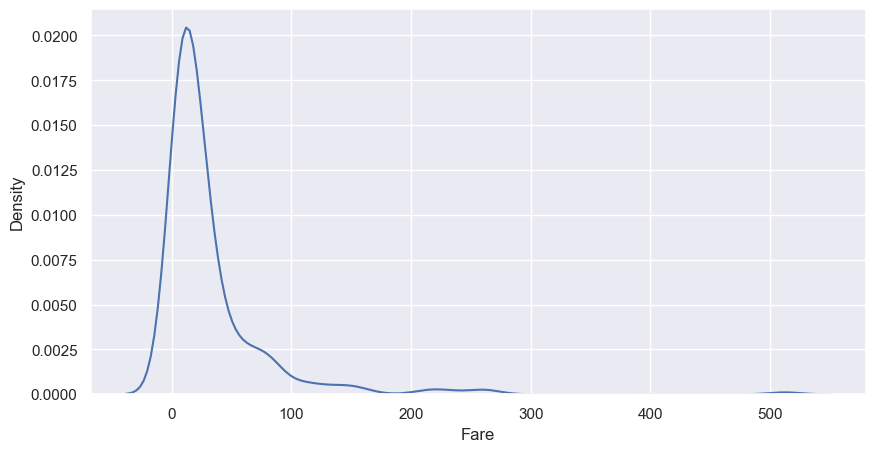

In [6]:
plt.figure(figsize=(10,5))
sns.kdeplot(titanic_df["Fare"]);


#### Histograma
También podemos verlo en un histograma.

[Documentación](https://seaborn.pydata.org/generated/seaborn.histplot.html)

Los histogramas dan la frecuencia de aparición de todos los valores. Muy similar al diagrama de densidad anterior. La diferencia es que ahora el eje y es un conteo y no la densidad de probabilidad de los valores de la variable.

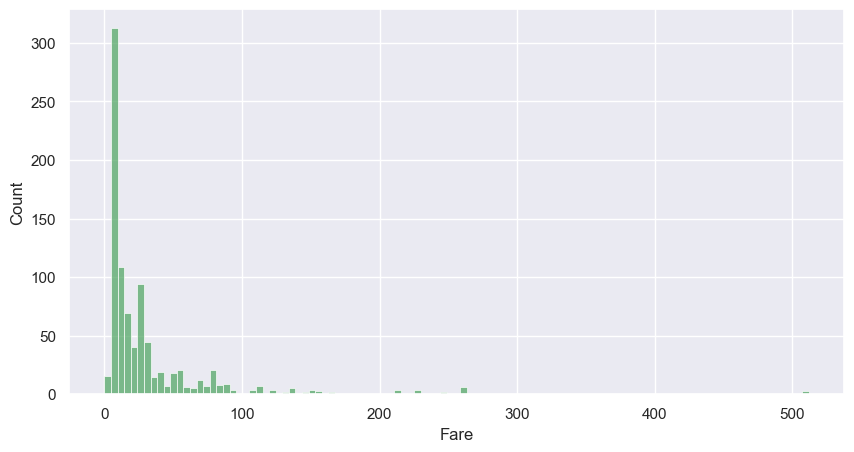

In [7]:
plt.figure(figsize=(10,5))
sns.histplot(titanic_df["Fare"], kde=False, color = "g");

Podemos agrupar (visualmente) una variable numérica. Podría ser una posible categorización de los billetes:

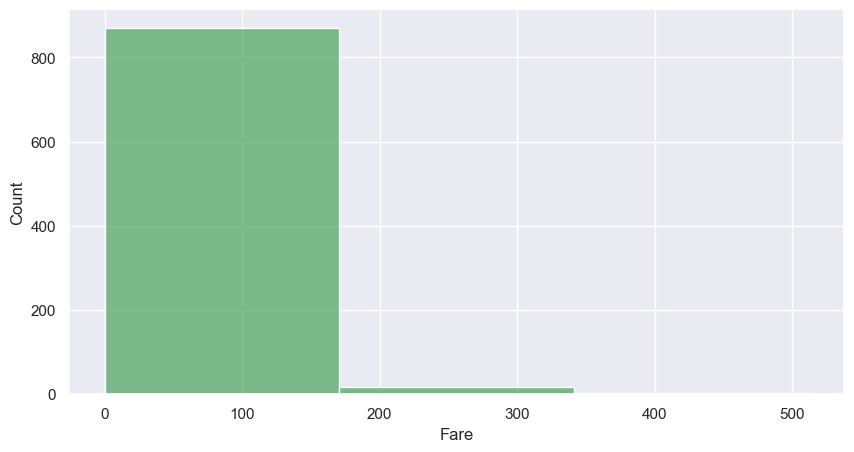

In [8]:
plt.figure(figsize=(10,5))
sns.histplot(titanic_df["Fare"], kde=False, color="g", bins = 3);


#### Histograma + Densidad



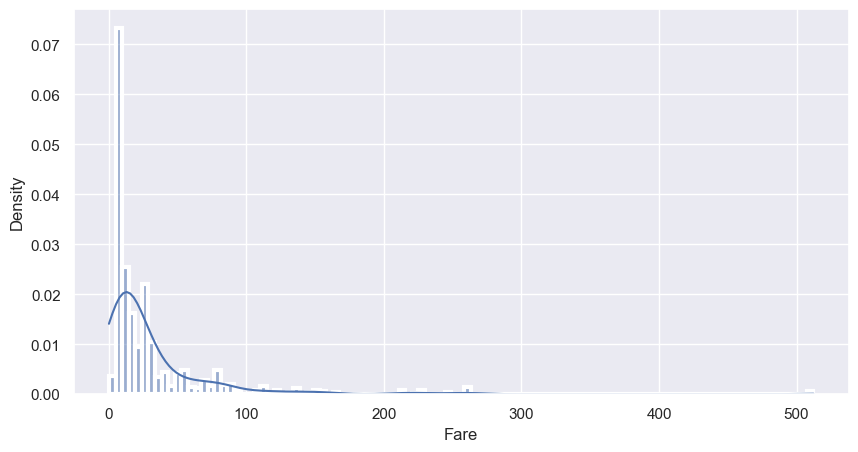

In [9]:
plt.figure(figsize=(10,5))
sns.histplot(titanic_df["Fare"],kde=True, stat="density", linewidth=3);



Otra manera muy visual de ver la concentración de los valores es añadir un `rugplot`, que marca cada observación con una pequeña raya sobre el eje:

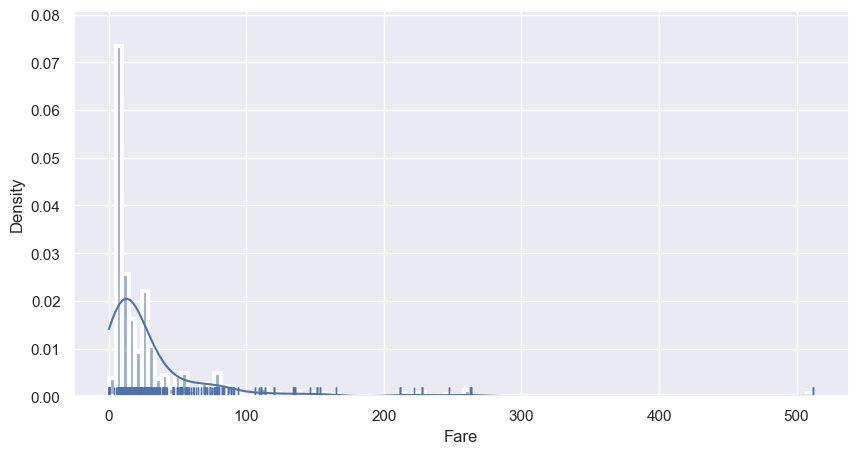

In [10]:
plt.figure(figsize=(10,5))
sns.histplot(titanic_df["Fare"], kde=True, stat="density", linewidth=3);

sns.rugplot(titanic_df["Fare"]);

#### Boxplot

[Colores de Matplotlib](https://matplotlib.org/stable/gallery/color/named_colors.html)

[Boxplot](https://seaborn.pydata.org/generated/seaborn.boxplot.html)

Los boxplots dan una información muy parecida a los gráficos vistos anteriormente, aunque en este caso destacan mucho más los outliers.

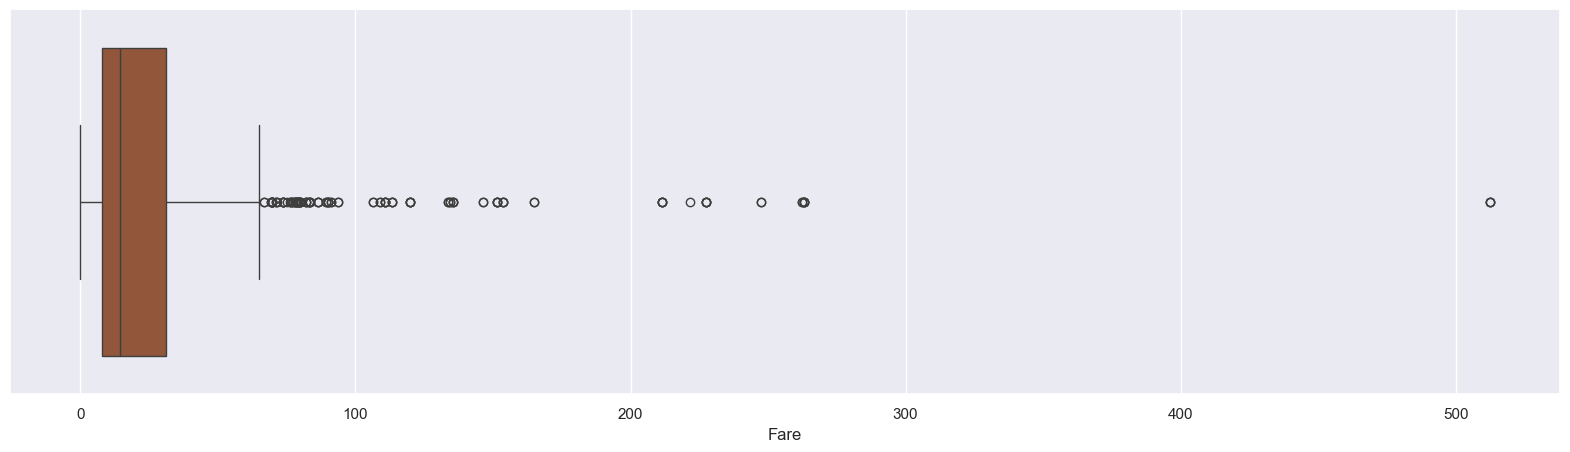

In [11]:
plt.figure(figsize=(20,5))
sns.boxplot(x=titanic_df["Fare"], color="sienna");

![imagen](../img/boxplot.png)

#### Violinplot

[Colores de Matplotlib](https://matplotlib.org/stable/gallery/color/named_colors.html)

[Violinplot](https://seaborn.pydata.org/generated/seaborn.violinplot.html)

Igual que un diagrama de caja, pero en este caso muestra la función de densidad en lugar de la propia caja.

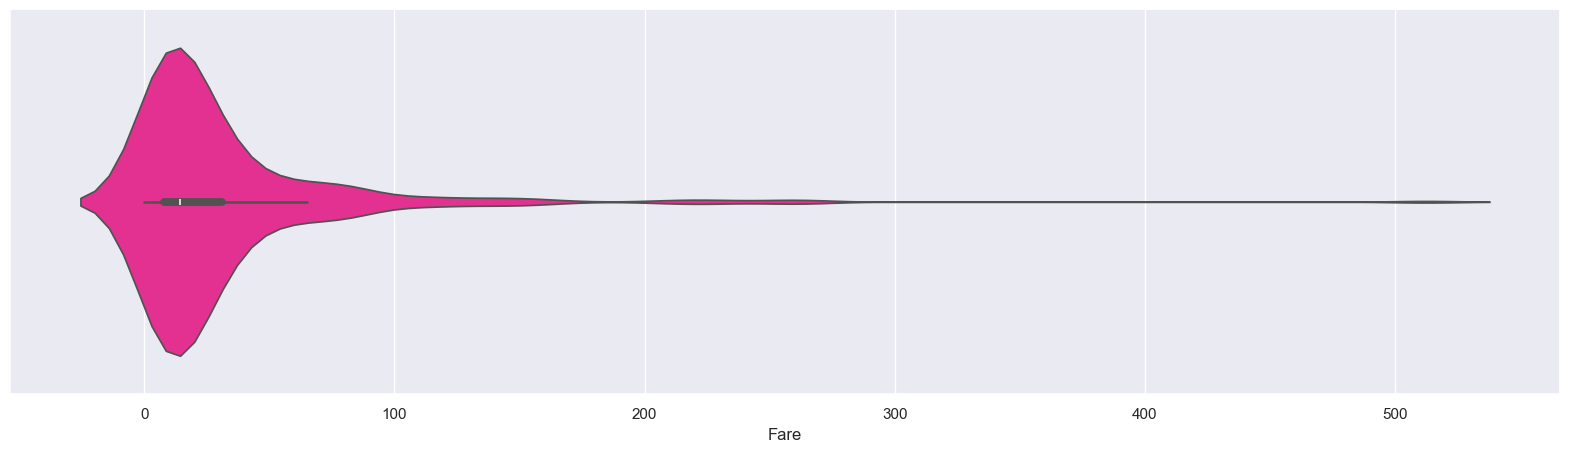

In [12]:
plt.figure(figsize=(20,5))
sns.violinplot(x=titanic_df["Fare"], color="deeppink");

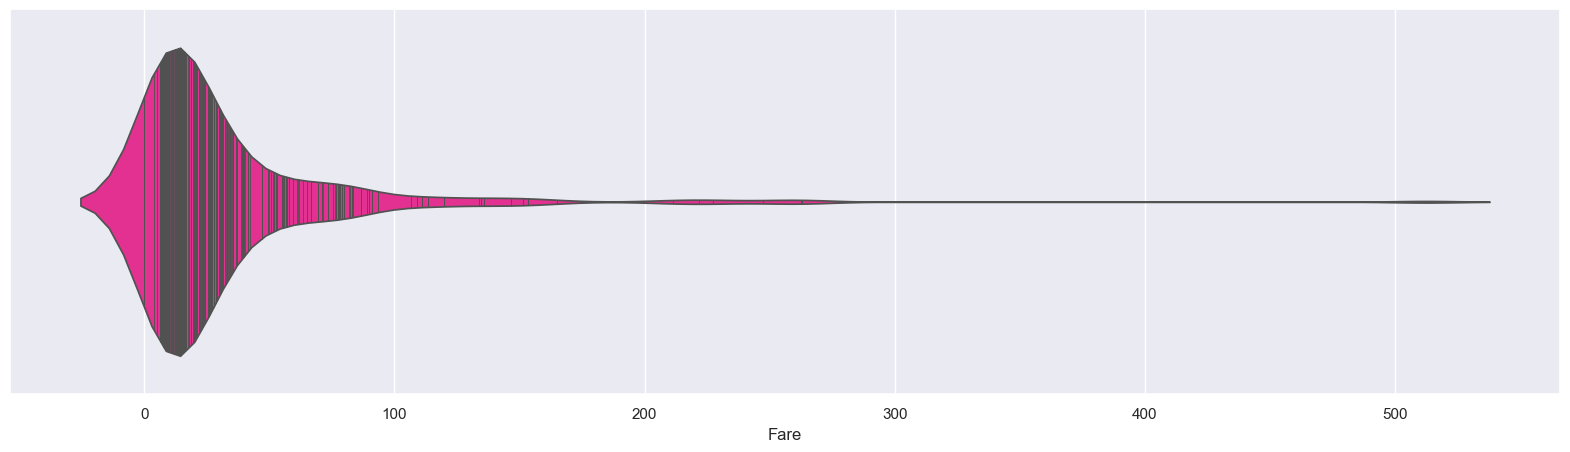

In [13]:
plt.figure(figsize=(20,5))
sns.violinplot(x=titanic_df["Fare"], color="deeppink", inner="stick");

### 1.2 Variables cualitativas
Para representar una variable categórica tendremos que ver su frecuencia de valores.

En este caso vamos a ver qué puerto de embarque ha sido el más frecuente.

[Documentación](https://seaborn.pydata.org/generated/seaborn.countplot.html)

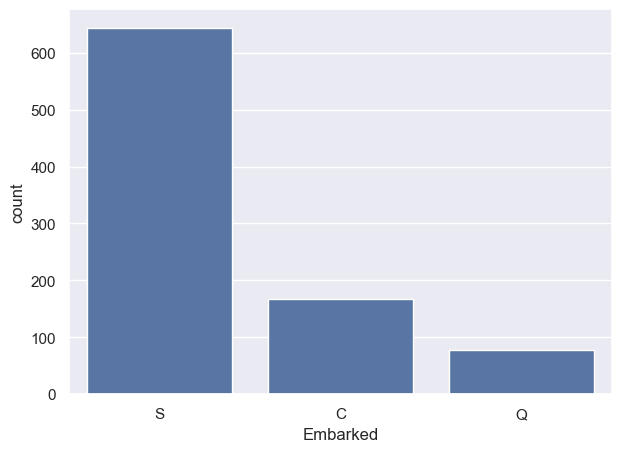

In [14]:
plt.figure(figsize=(7,5))
sns.countplot(x = titanic_df["Embarked"]);

#### Lollipop

¿Cuáles han sido los productos más pedidos?

[Documentación](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hlines.html)

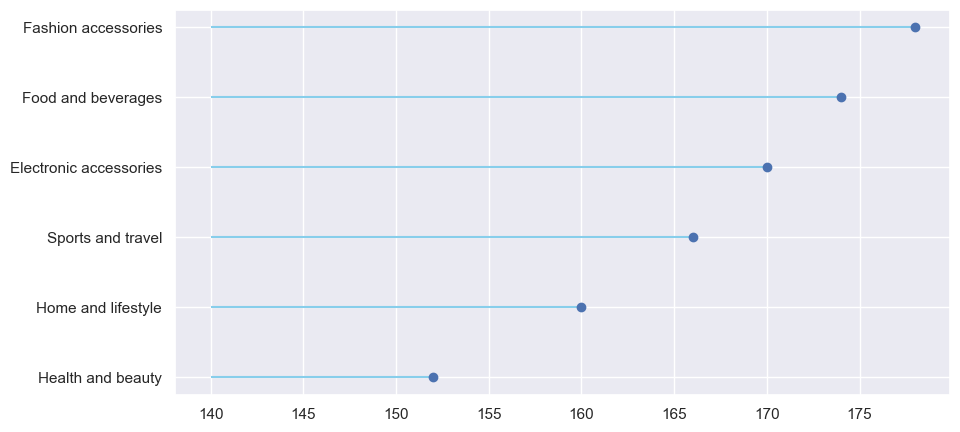

In [15]:
conteo = market_df['Product line'].value_counts(ascending=True)

plt.figure(figsize=(10,5))
plt.hlines(y=conteo.index,
           xmin=140,
           xmax=conteo,
           color='skyblue')
plt.plot(conteo, conteo.index, "o");


#### Donut chart/Pie chart

[Documentación](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.pie.html)

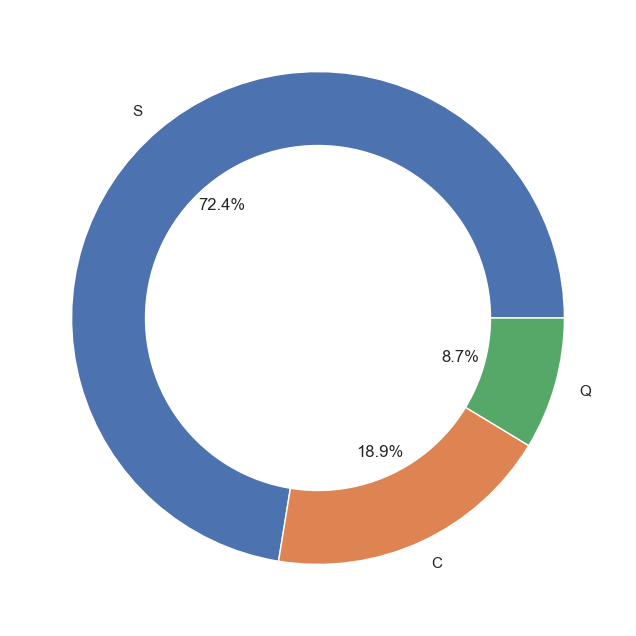

In [16]:
# Datos
data = titanic_df["Embarked"].value_counts()

plt.figure(figsize=(8,8))
plt.pie(data.values,
        labels=data.index,
        autopct='%1.1f%%')

# Un círculo blanco en el centro convierte la tarta en un donut
my_circle = plt.Circle((0,0), 0.7, color='white')
plt.gca().add_artist(my_circle);

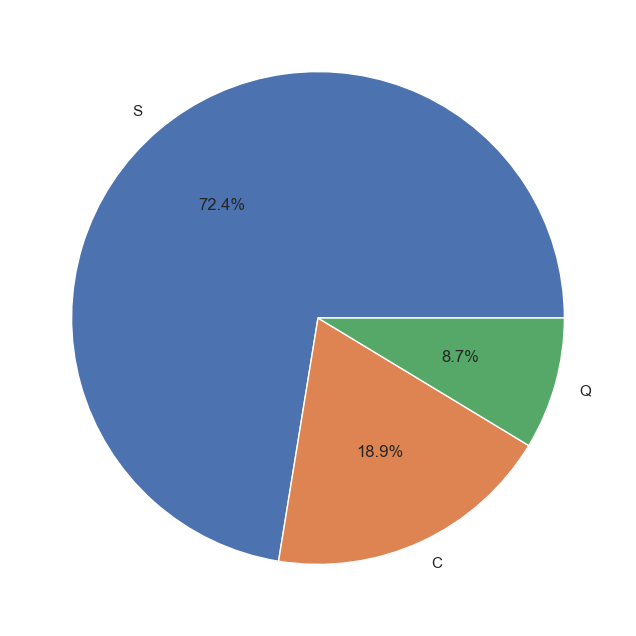

In [17]:
# Pie chart
plt.figure(figsize=(8,8))
plt.pie(data.values,
        labels=data.index,
        autopct='%1.1f%%');

## 2. Análisis Bivariante
### 2.1 Comparativa de variables cuantitativas (2-4 variables)
#### Boxplot

En este ejemplo veremos cómo de diferentes son las distribuciones de las 4 características que definen a una flor.

[Boxplot](https://seaborn.pydata.org/generated/seaborn.boxplot.html)

In [18]:
# Las 4 primeras columnas son las características numéricas
iris_df.columns.values[:4]

array(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)'], dtype=object)

El boxplot está bien, pero hay algo de información que se nos escapa: no vemos cuántos puntos hay ni cómo se reparten dentro de la caja.

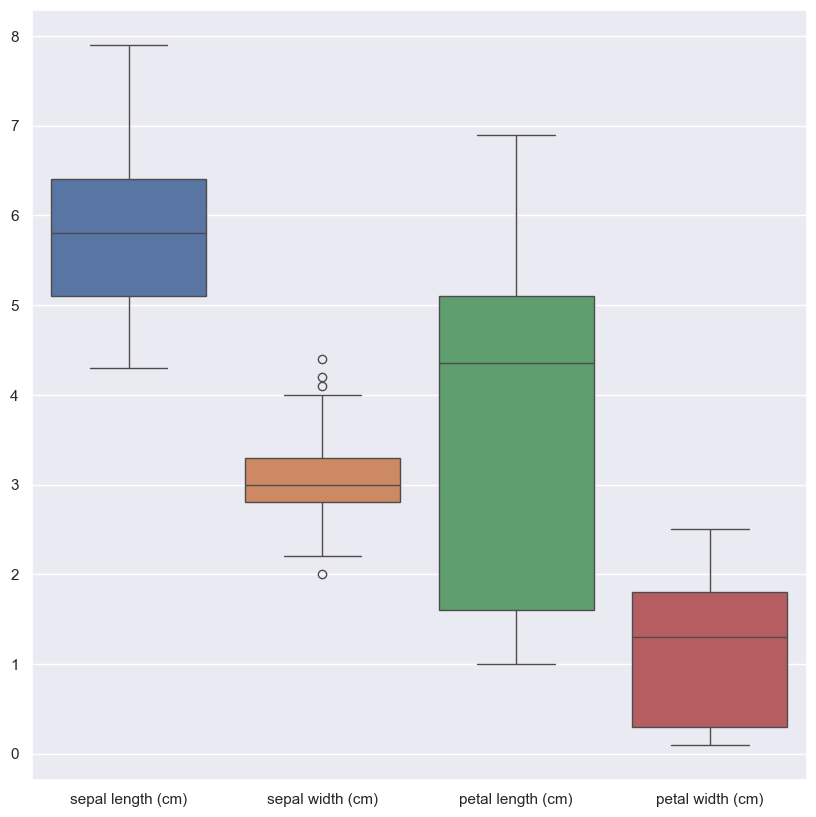

In [19]:
plt.figure(figsize=(10,10))
sns.boxplot(data=iris_df[iris_df.columns.values[0:4]]);

Si pintamos además los puntos encima de las cajas, lo vemos:

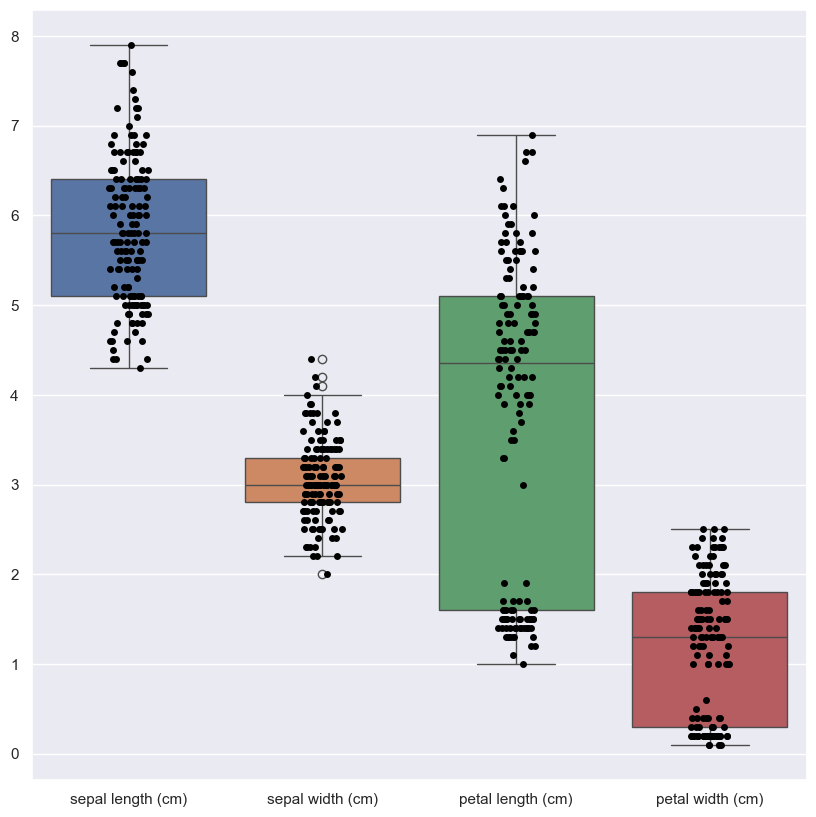

In [20]:
plt.figure(figsize=(10,10))
sns.boxplot(data=iris_df[iris_df.columns.values[0:4]])
sns.stripplot(data=iris_df[iris_df.columns.values[0:4]], color='black');
# Alternativa: sns.swarmplot, que evita que los puntos se solapen

#### Diagramas de densidad

Otra manera de ver cómo se distribuyen las características de las flores.

[Documentación](https://seaborn.pydata.org/generated/seaborn.kdeplot.html)

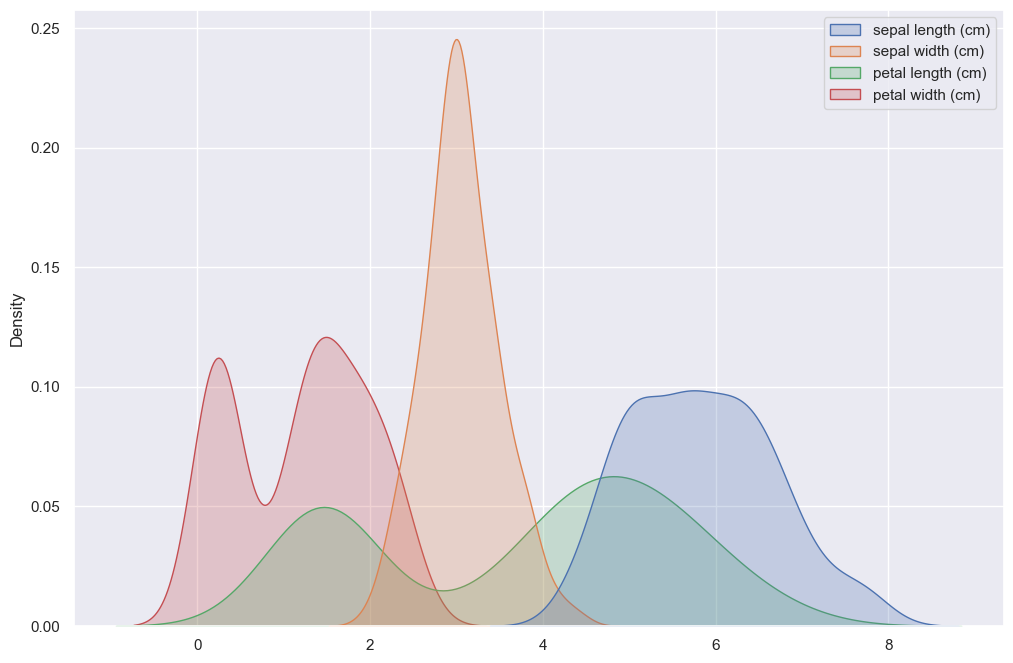

In [21]:
plt.figure(figsize=(12,8))
sns.kdeplot(data = iris_df[iris_df.columns.values[:4]], fill = True);

#### Histogramas

[Documentación](https://seaborn.pydata.org/generated/seaborn.histplot.html)

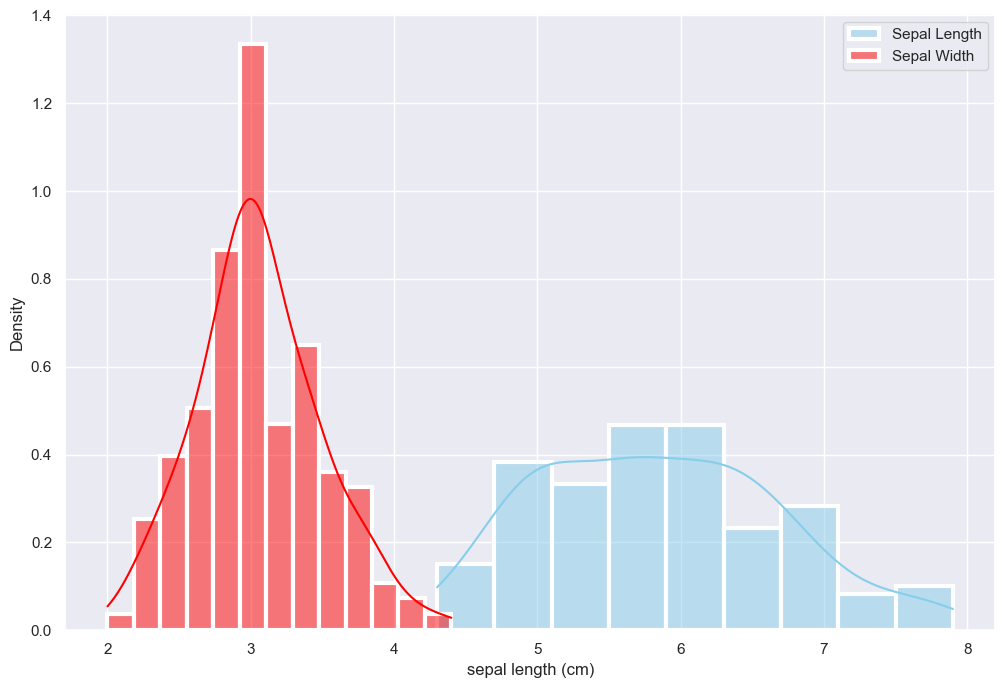

In [22]:
plt.figure(figsize=(12,8))
sns.histplot(iris_df["sepal length (cm)"] , color="skyblue", label="Sepal Length", kde=True, stat="density", linewidth=3)
sns.histplot(iris_df["sepal width (cm)"] , color="red", label="Sepal Width", kde=True, stat="density", linewidth=3)
plt.legend();

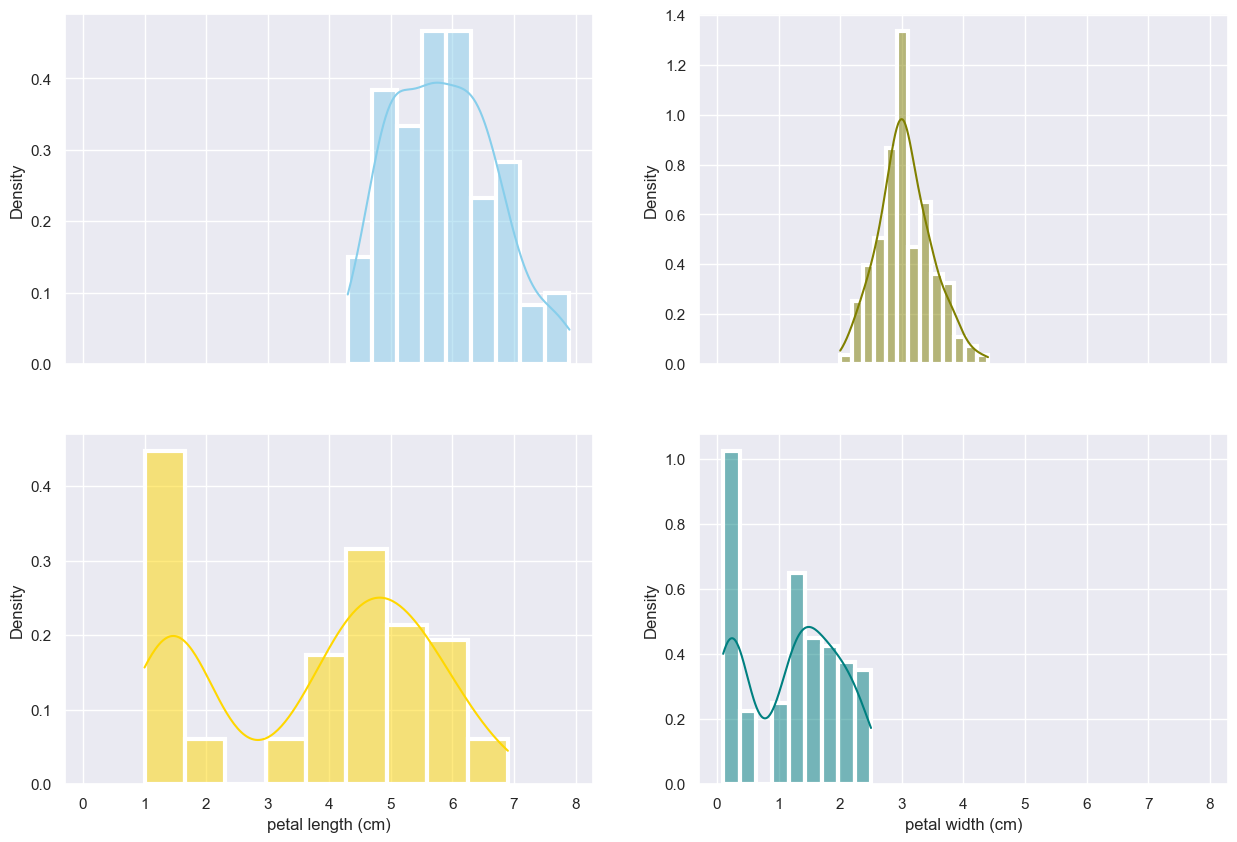

In [23]:
f, axes = plt.subplots(2, 2, figsize=(15,10), sharex=True)
sns.histplot(iris_df["sepal length (cm)"] , color="skyblue", ax=axes[0, 0], kde=True, stat="density", linewidth=3)
sns.histplot(iris_df["sepal width (cm)"] , color="olive", ax=axes[0, 1], kde=True, stat="density", linewidth=3)
sns.histplot(iris_df["petal length (cm)"] , color="gold", ax=axes[1, 0], kde=True, stat="density", linewidth=3)
sns.histplot(iris_df["petal width (cm)"] , color="teal", ax=axes[1, 1], kde=True, stat="density", linewidth=3);

#### Scatter plot

En este ejemplo se ve claramente cómo estas dos variables sirven para distinguir las setosas de los otros tipos.

[Documentación](https://seaborn.pydata.org/generated/seaborn.scatterplot.html)

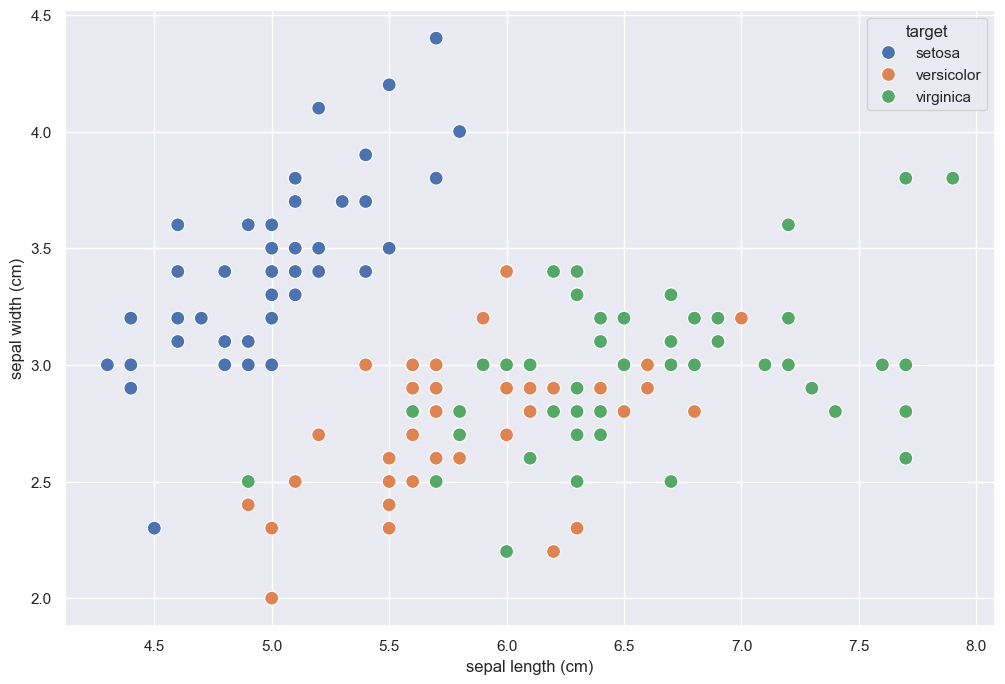

In [24]:
plt.figure(figsize=(12,8))
sns.scatterplot(x = iris_df["sepal length (cm)"],
y = iris_df["sepal width (cm)"],
s = 100,
hue = iris_df["target"]);

#### Jointplot

Para ver dos variables numéricas a la vez que sus distribuciones usaremos el dataset *California housing* (viviendas de California por zona censal). Lo tenemos guardado en `data/`; también se puede descargar con `sklearn.datasets.fetch_california_housing`.

[Documentación dataset](https://scikit-learn.org/stable/datasets/real_world.html#california-housing-dataset)

[Documentación jointplot](https://seaborn.pydata.org/generated/seaborn.jointplot.html)

Población de cada zona (en escala logarítmica) vs media de habitaciones por vivienda:

In [25]:
california_df = pd.read_csv("../data/california_housing.csv")

In [26]:
california_df.shape

(20640, 9)

In [27]:
california_df.head(2)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.02381,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.97188,2401.0,2.109842,37.86,-122.22,3.585


La media de habitaciones tiene algunos valores extremos que aplastan el gráfico, así que nos quedamos con las zonas de menos de 15 habitaciones de media:

In [28]:
california_df = california_df[california_df['AveRooms'] < 15]

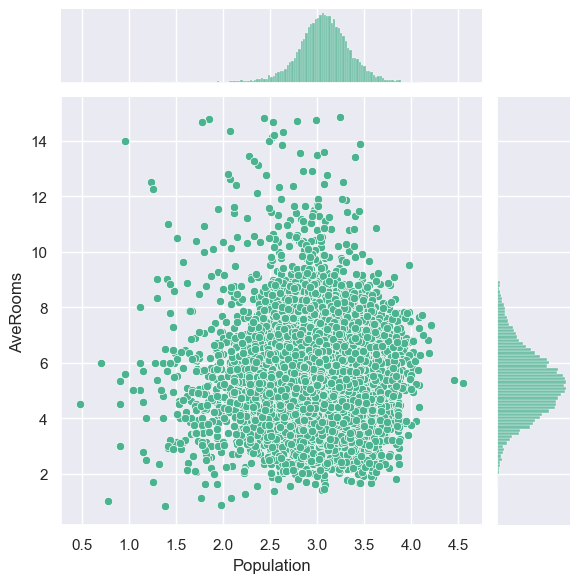

In [29]:
sns.jointplot(x = np.log10(california_df['Population']),
        y = california_df['AveRooms'],
        color = '#4Cb391');

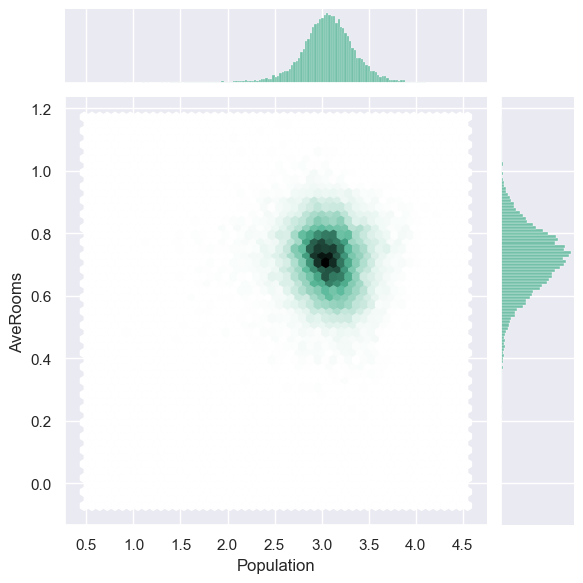

In [30]:
sns.jointplot(x = np.log10(california_df['Population']),
        y = np.log10(california_df['AveRooms']),
        kind = "hex",
        color = '#4Cb391');

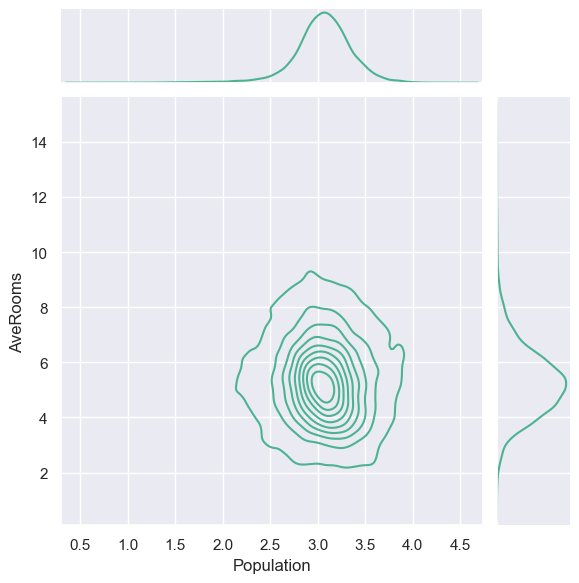

In [31]:
sns.jointplot(x = np.log10(california_df['Population']),
        y = california_df['AveRooms'],
        kind = "kde",
        color = '#4Cb391');

### 2.2 Comparativa de múltiples numéricas

#### Heatmaps

Los heatmaps son perfectos para representar una matriz de correlación.

[Documentación heatmap](https://seaborn.pydata.org/generated/seaborn.heatmap.html)

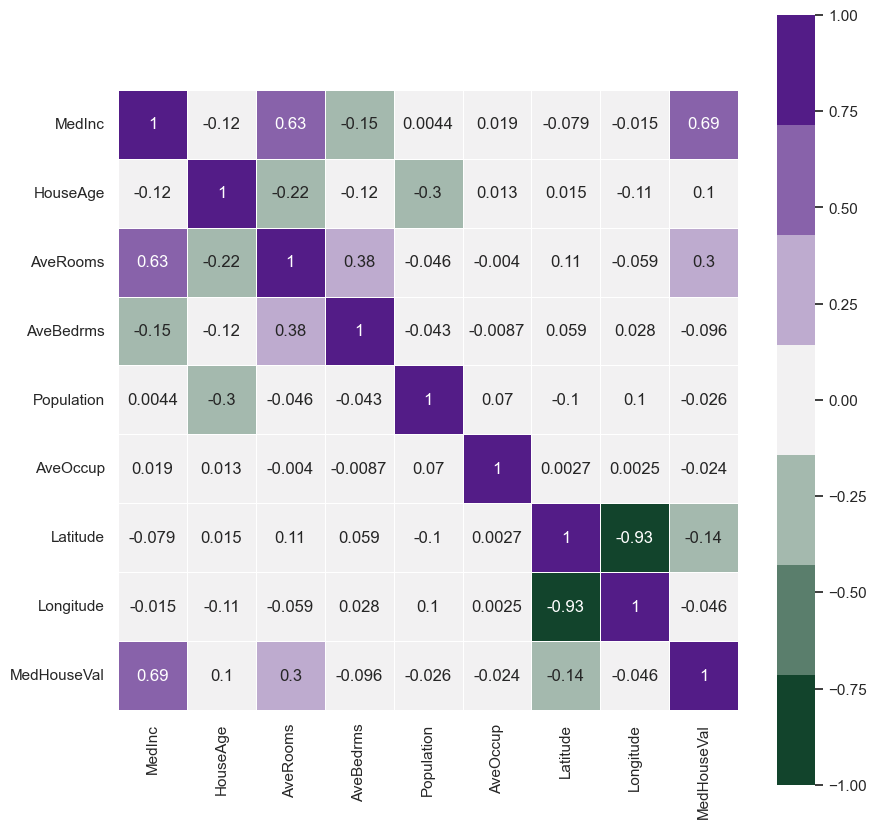

In [32]:
plt.figure(figsize=(10,10))
sns.heatmap(california_df.corr(),
vmin = -1,
vmax = 1,
cmap = sns.diverging_palette(145, 280, s=85, l=25, n=7),
annot = True,
square = True,
linewidth = .5);

También nos permite comparar una variable numérica frente a dos variables categóricas. 

Se recomienda que las dos variables categóricas tengan pocas categorías, porque si no, no se va a ver bien el heatmap.

In [33]:
data = market_df.groupby(["Product line", "Payment"])["Quantity"].sum().unstack()
data = data.loc[["Electronic accessories", "Fashion accessories", "Food and beverages"]]

In [34]:
data

Payment,Cash,Credit card,Ewallet
Product line,,,
Electronic accessories,398,262,311
Fashion accessories,280,293,329
Food and beverages,295,335,322


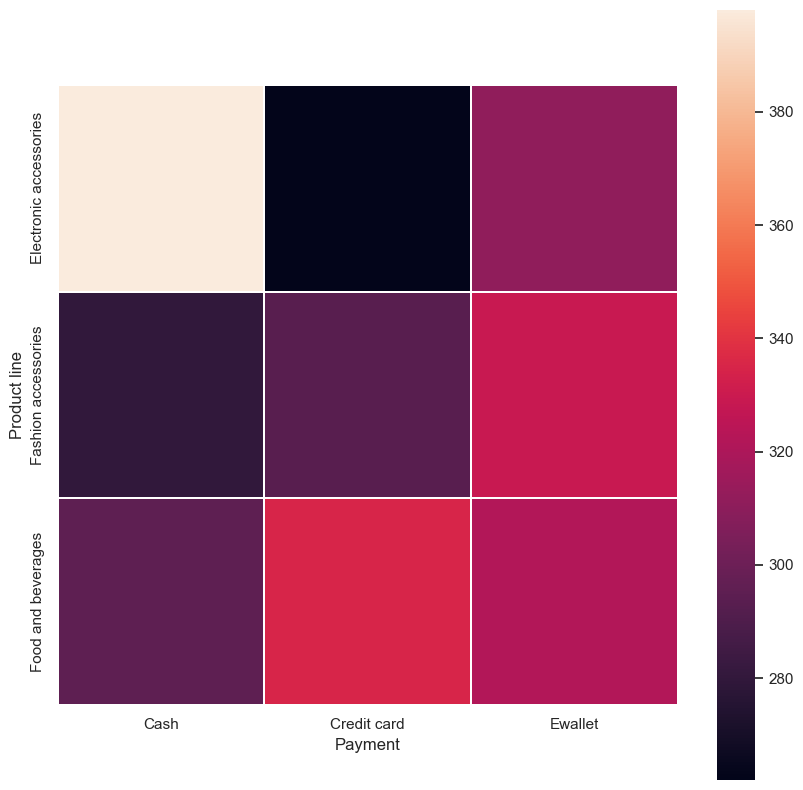

In [35]:
plt.figure(figsize=(10,10))
sns.heatmap(data,
square=True,
linewidths = .3);

#### Correlograma

[Documentación Pairplot](https://seaborn.pydata.org/generated/seaborn.pairplot.html)

Interesante gráfica para ver en un dataset qué variables presentan correlación lineal, así como sus distribuciones. NO realices esta gráfica con muchas variables porque no se va a ver bien. Hazlo por partes.

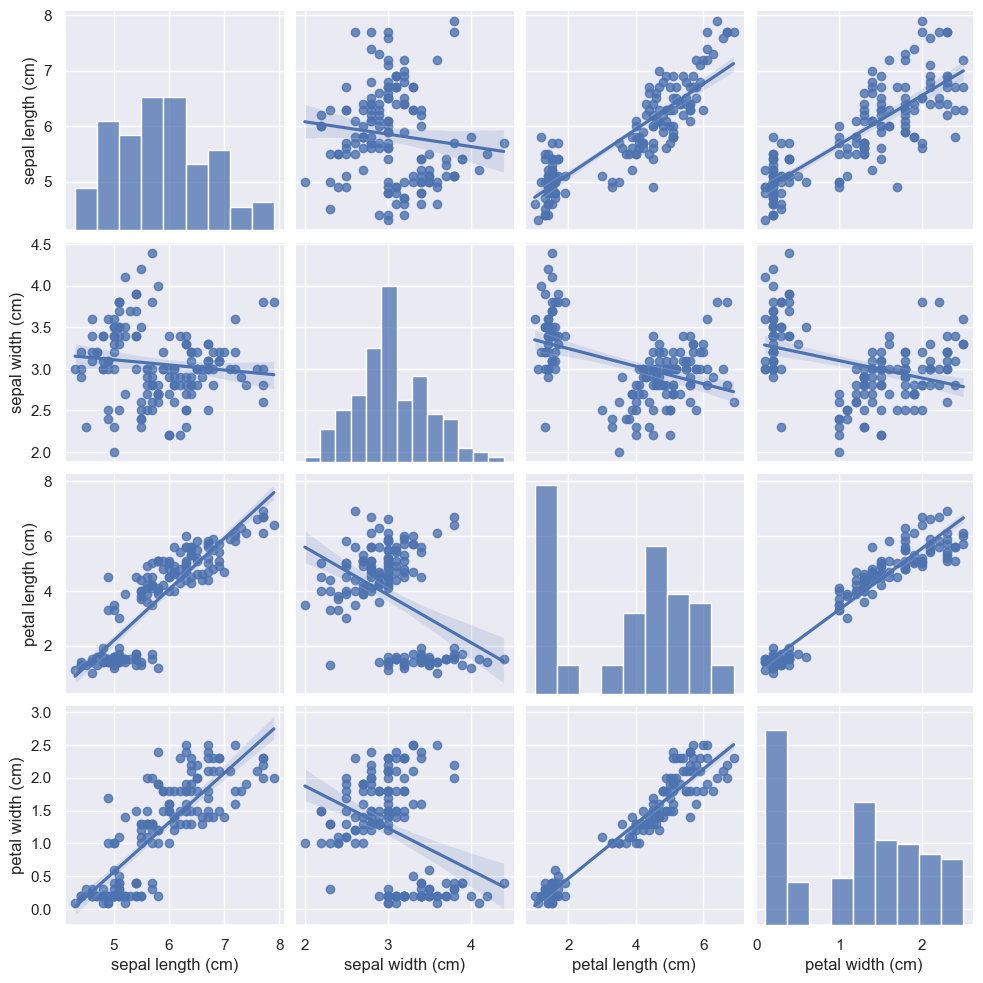

In [36]:
sns.pairplot(iris_df,
kind = "reg");

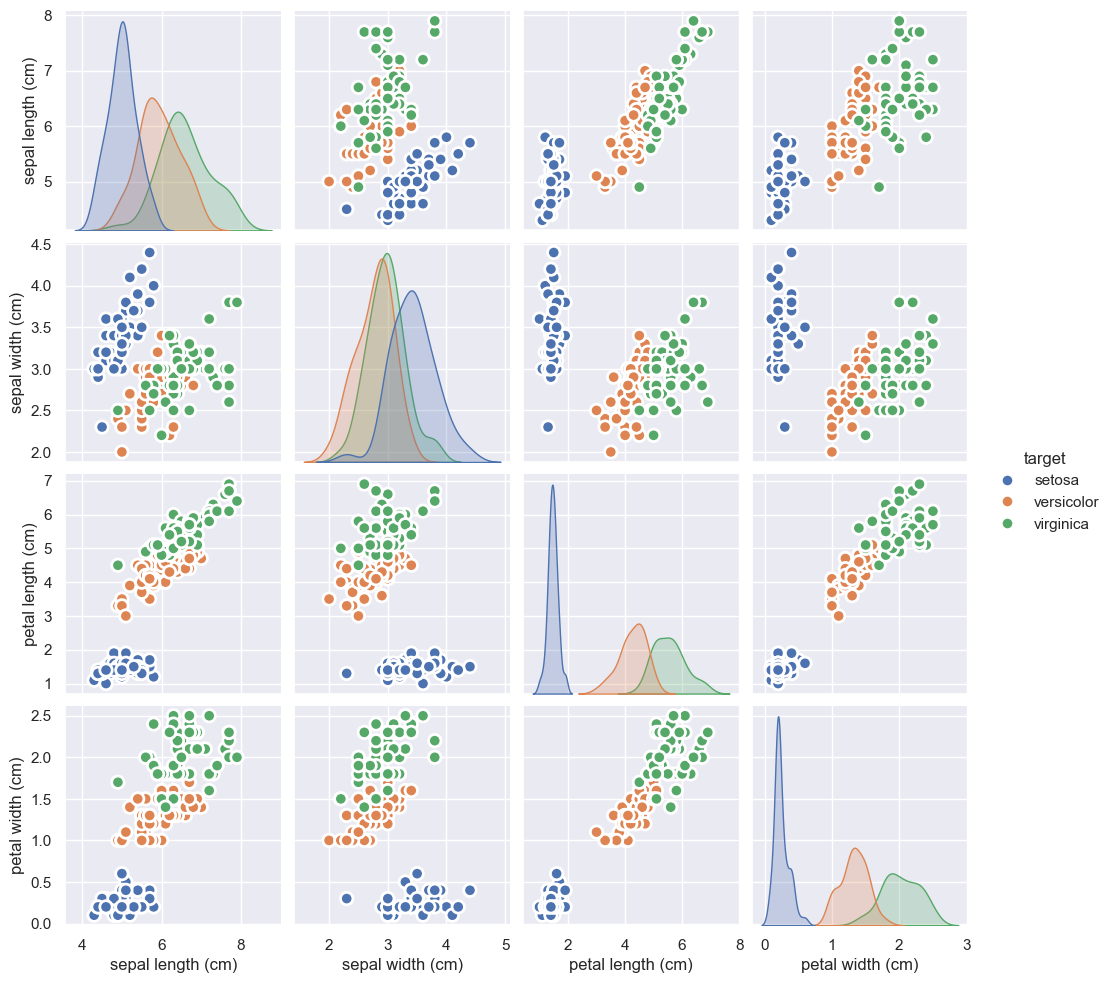

In [37]:
sns.pairplot(iris_df,
kind = "scatter",
hue = "target",
plot_kws = dict(s = 80, edgecolor = "white", linewidth = 2));

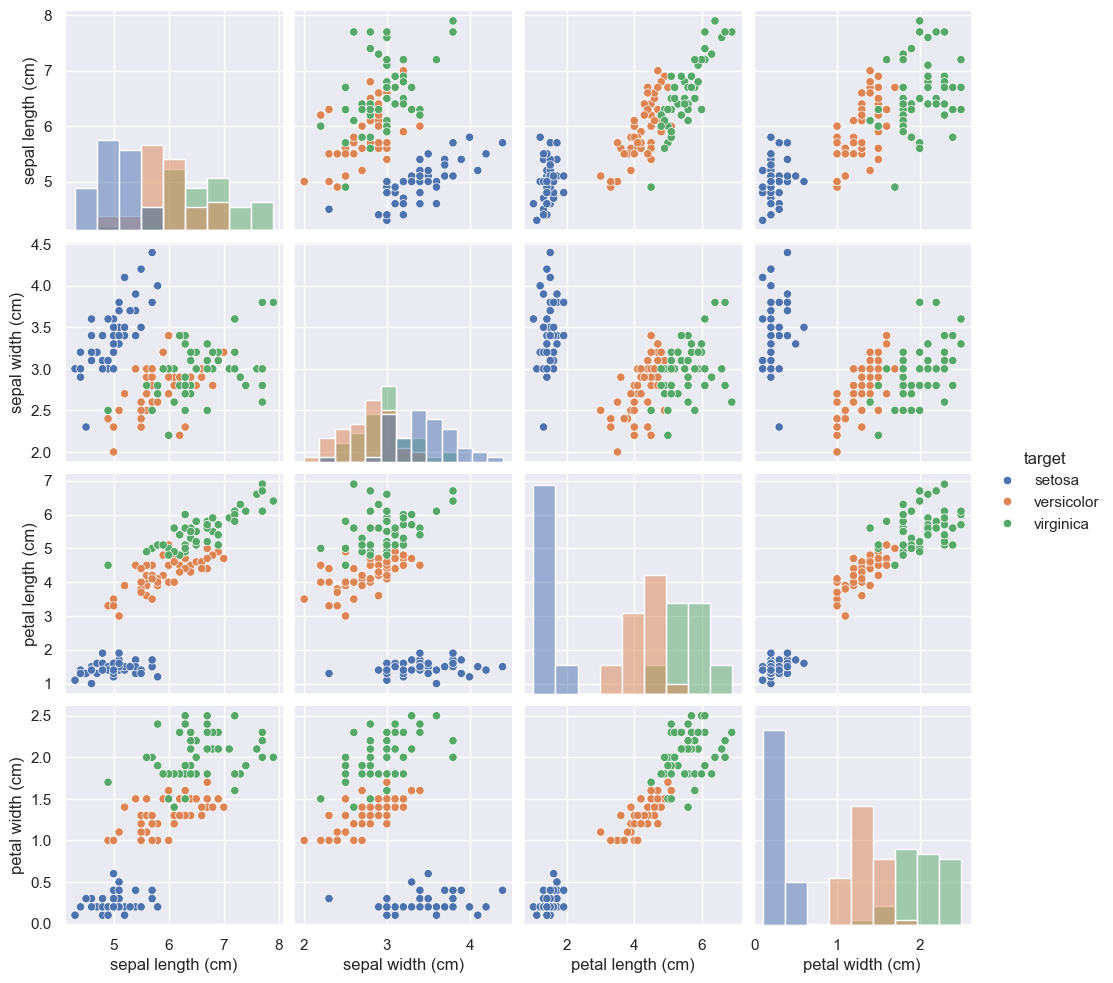

In [38]:
sns.pairplot(iris_df,
             kind="scatter",
             hue="target",
             diag_kind="hist");

### 2.3 Comparativa de dos variables cualitativas
#### Tabla

[Documentación](https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html)

Lo más sencillo, una tabla con la frecuencia de valores. Esto es factible cuando los elementos únicos por categoría no son muchos.

In [39]:
pd.crosstab(titanic_df["Embarked"],
            titanic_df["Sex"])

Sex,female,male
Embarked,,
C,73,95
Q,36,41
S,203,441


#### Diagrama de barras

[Documentación](https://seaborn.pydata.org/generated/seaborn.catplot.html)

En un diagrama de barras también se pueden representar dos variables cualitativas:

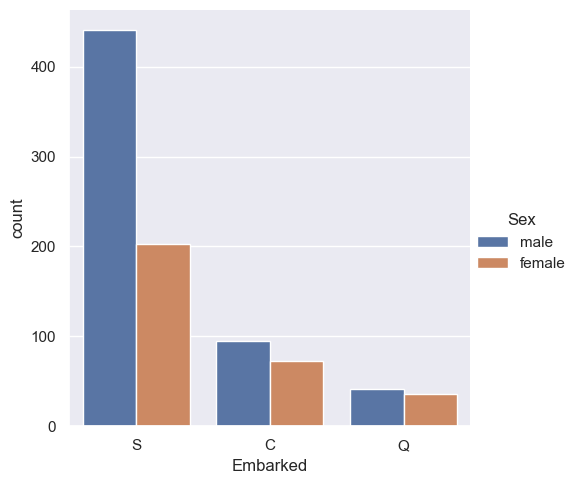

In [40]:
sns.catplot(x="Embarked",
            hue="Sex",
            kind="count",
            data=titanic_df);

Otra manera de visualizar dos o más variables categóricas:

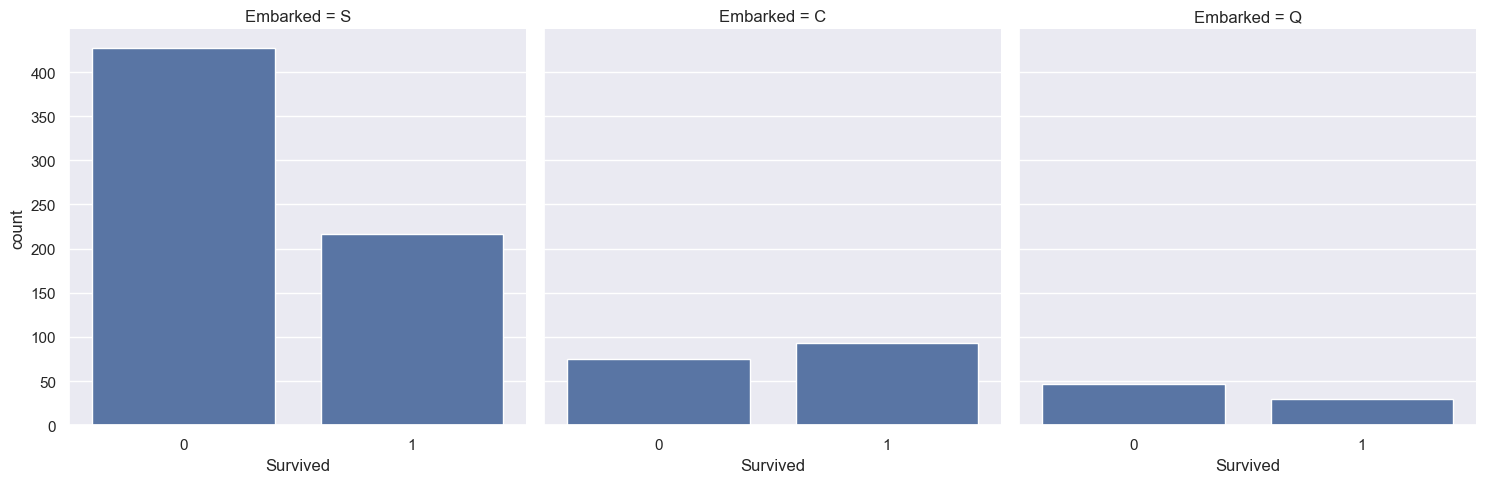

In [41]:
sns.catplot(x="Survived",
            col="Embarked",
            col_wrap=3,
            data=titanic_df,
            kind="count");

O con un diagrama de barras apiladas, preparando antes la tabla de frecuencias con pandas:

In [42]:
df_plot = titanic_df.groupby(['Embarked', 'Survived']).size().unstack(level='Embarked')
df_plot

Embarked,C,Q,S
Survived,,,
0,75,47,427
1,93,30,217


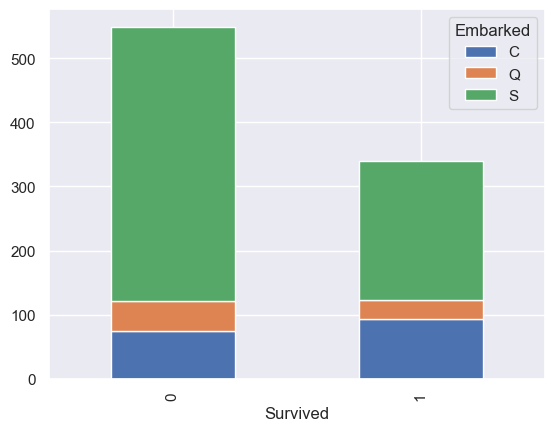

In [43]:
df_plot.plot(kind='bar', stacked=True);

### 2.4 Cualitativa vs cuantitativa
#### Series temporales

[Documentación](https://seaborn.pydata.org/generated/seaborn.lineplot.html)

Las series temporales tienen la particularidad de que son datos ordenados.

Usaremos un dataset de festivos y eventos de Ecuador. Contaremos cuántos festivos, eventos y puentes hay cada año según su ámbito (`locale`: local, regional o nacional).

In [44]:
eventos_df = pd.read_csv("../data/holidays_events.csv")
eventos_df.head()

,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False


In [45]:
eventos_df.type.unique()

array(['Holiday', 'Transfer', 'Additional', 'Bridge', 'Work Day', 'Event'],
      dtype=object)

In [46]:
eventos_df = eventos_df.loc[eventos_df.type.isin(["Holiday", "Event", "Bridge"]), :].copy()
eventos_df["year"] = eventos_df["date"].str[:4].astype(int)

eventos_anuales = eventos_df.groupby(["locale", "year"]).size().reset_index(name="num_eventos")

In [47]:
eventos_anuales.head()

,locale,year,num_eventos
0,Local,2012,22
1,Local,2013,23
2,Local,2014,23
3,Local,2015,24
4,Local,2016,23


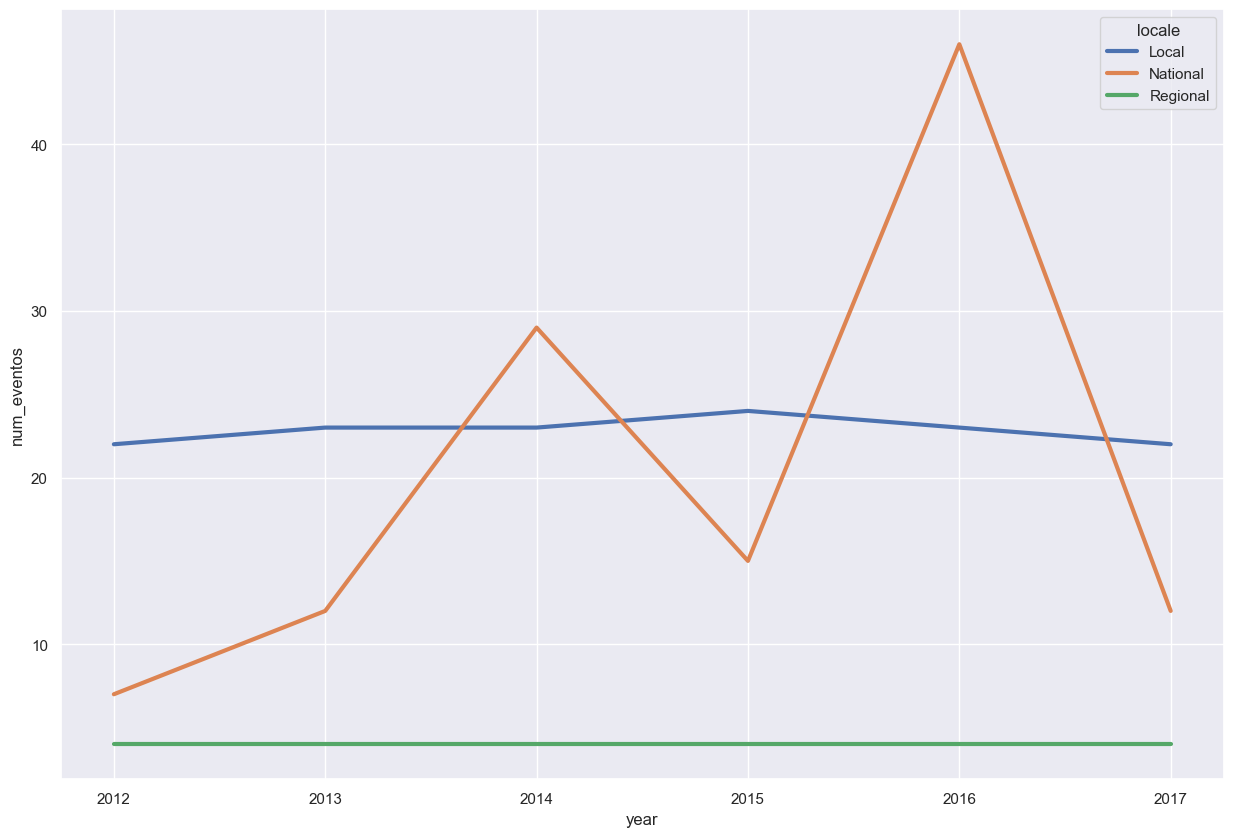

In [48]:
plt.figure(figsize=(15,10))
sns.lineplot(data=eventos_anuales,
             x="year",
             y="num_eventos",
             hue="locale",
             linewidth=3);

#### Treemap
Un treemap es una opción muy interesante para mostrar una variable numérica vs una categórica.

Seaborn no tiene treemaps, así que usaremos la librería `squarify`. Si no la tienes instalada, descomenta y ejecuta la siguiente celda.

In [49]:
# %pip install squarify

In [50]:
# Las 10 localidades con más festivos y eventos
data = eventos_df["locale_name"].value_counts()[:10]
data

locale_name
Ecuador        121
Riobamba        12
Guaranda        12
Latacunga       12
Ambato          12
Manta            6
Salinas          6
Loja             6
Quito            6
Santa Elena      6
Name: count, dtype: int64

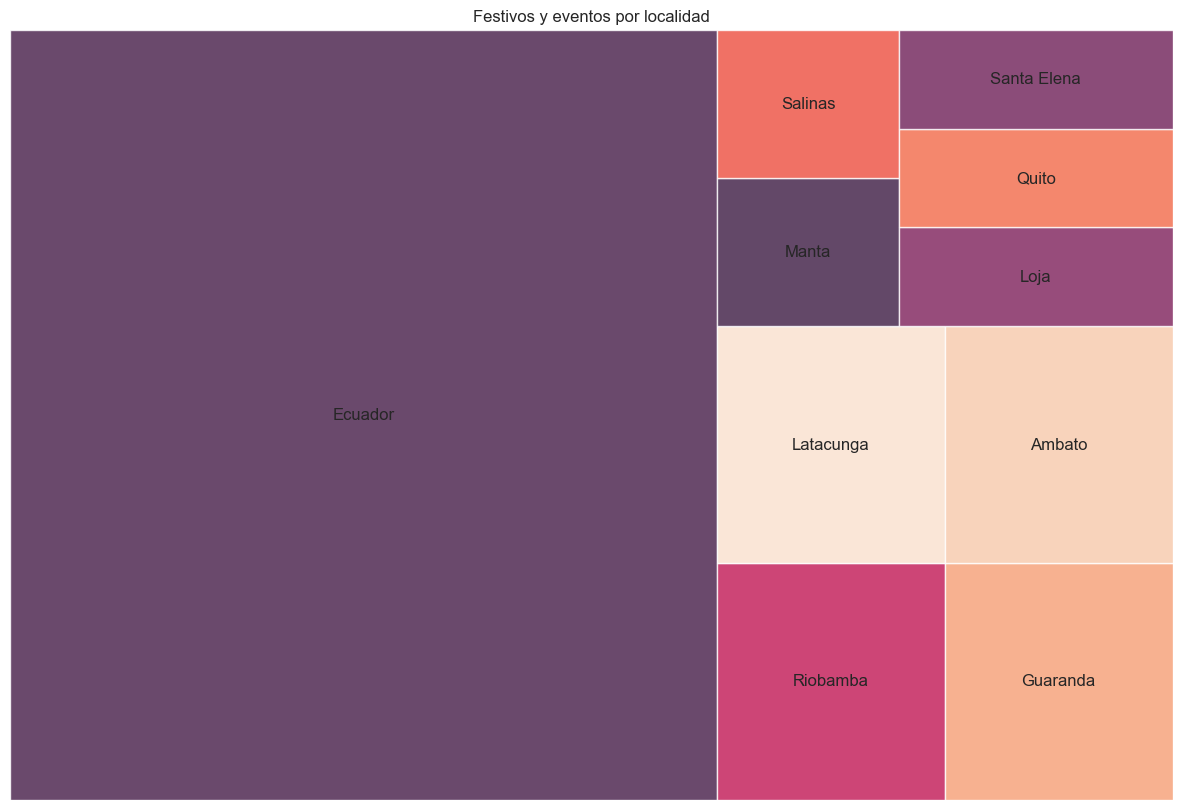

In [51]:
import squarify

plt.figure(figsize=(15,10))
squarify.plot(sizes=data.values, label=data.index, alpha=.8)
plt.axis('off')
plt.title("Festivos y eventos por localidad");

#### Catplot: dispersión, cajas y violines por categoría

Con este catplot obtenemos la dispersión de la variable Age para cada grupo de la categoría:

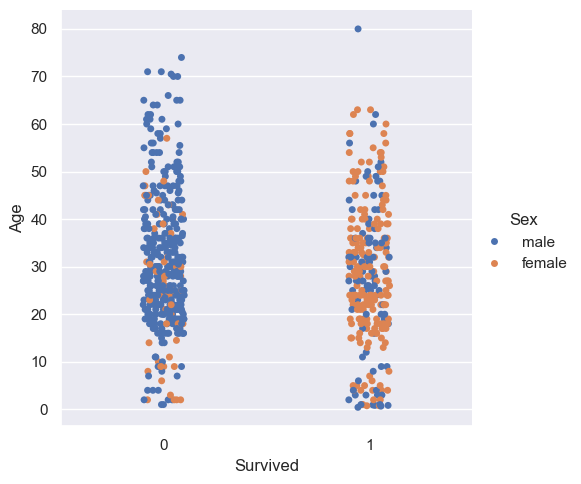

In [52]:
sns.catplot(x="Survived", y="Age", hue="Sex", data=titanic_df);

El equivalente con un diagrama de caja sería el siguiente:

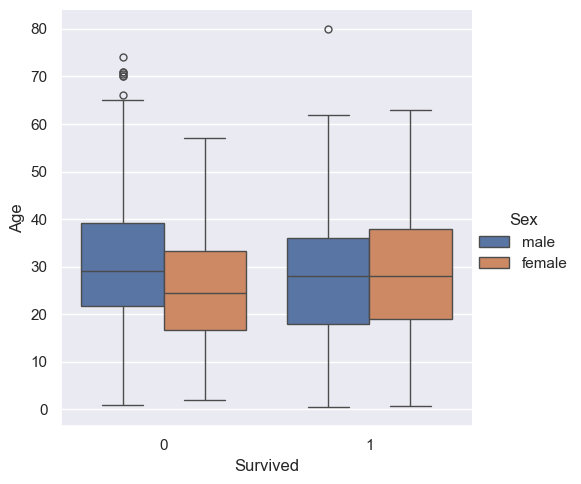

In [53]:
sns.catplot(x="Survived", y="Age", hue="Sex", kind="box", data=titanic_df);

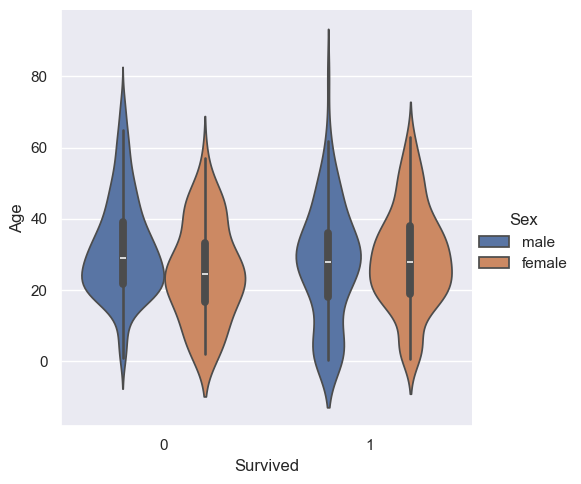

In [54]:
sns.catplot(x="Survived", y="Age", hue="Sex", kind="violin", data=titanic_df);

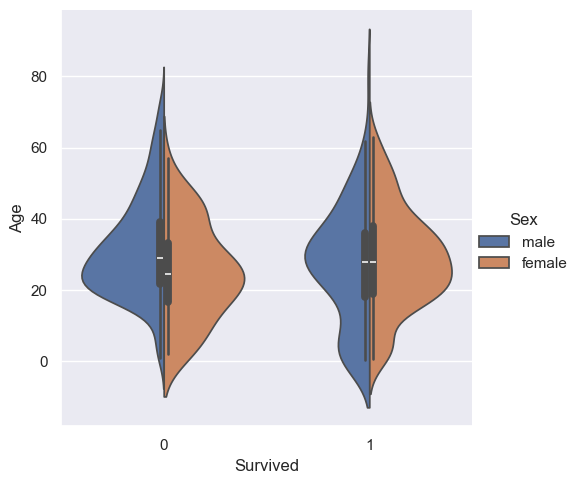

In [55]:
sns.catplot(x="Survived", y="Age", hue="Sex", kind="violin", split = True, data=titanic_df);

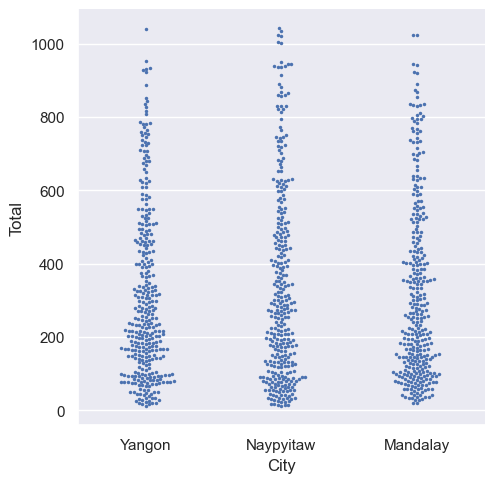

In [56]:
sns.catplot(x="City", y="Total", kind="swarm", size=2.5, data=market_df);

Podemos dividir además en varios gráficos con `col`. Por ejemplo, el total de cada compra por línea de producto y género en cada ciudad:

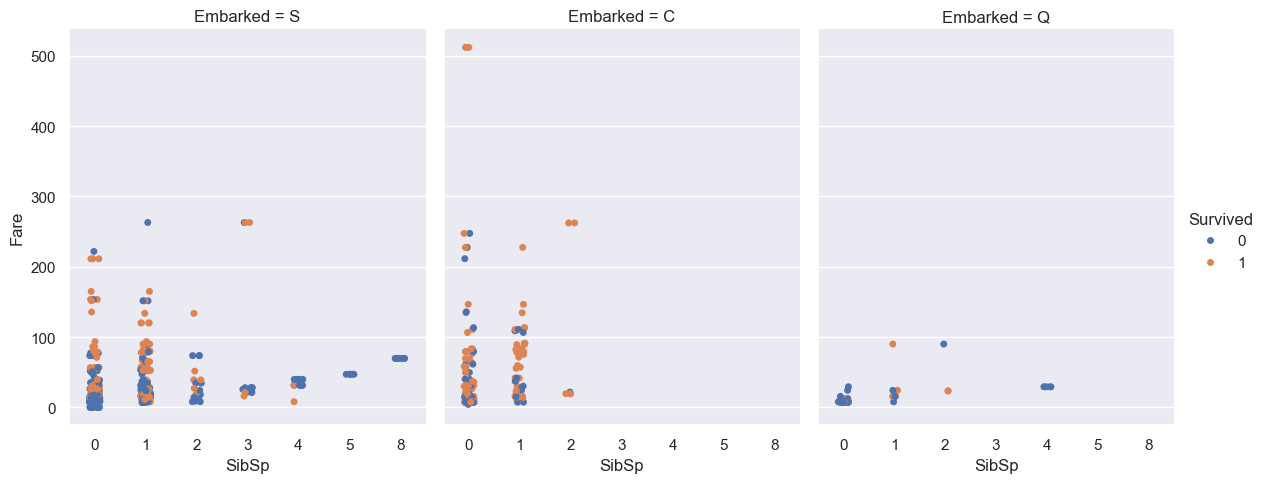

In [57]:
sns.catplot(x="SibSp",
            y="Fare",
            hue="Survived",
            col="Embarked",
            data=titanic_df,
            height=5,
            aspect=.8);

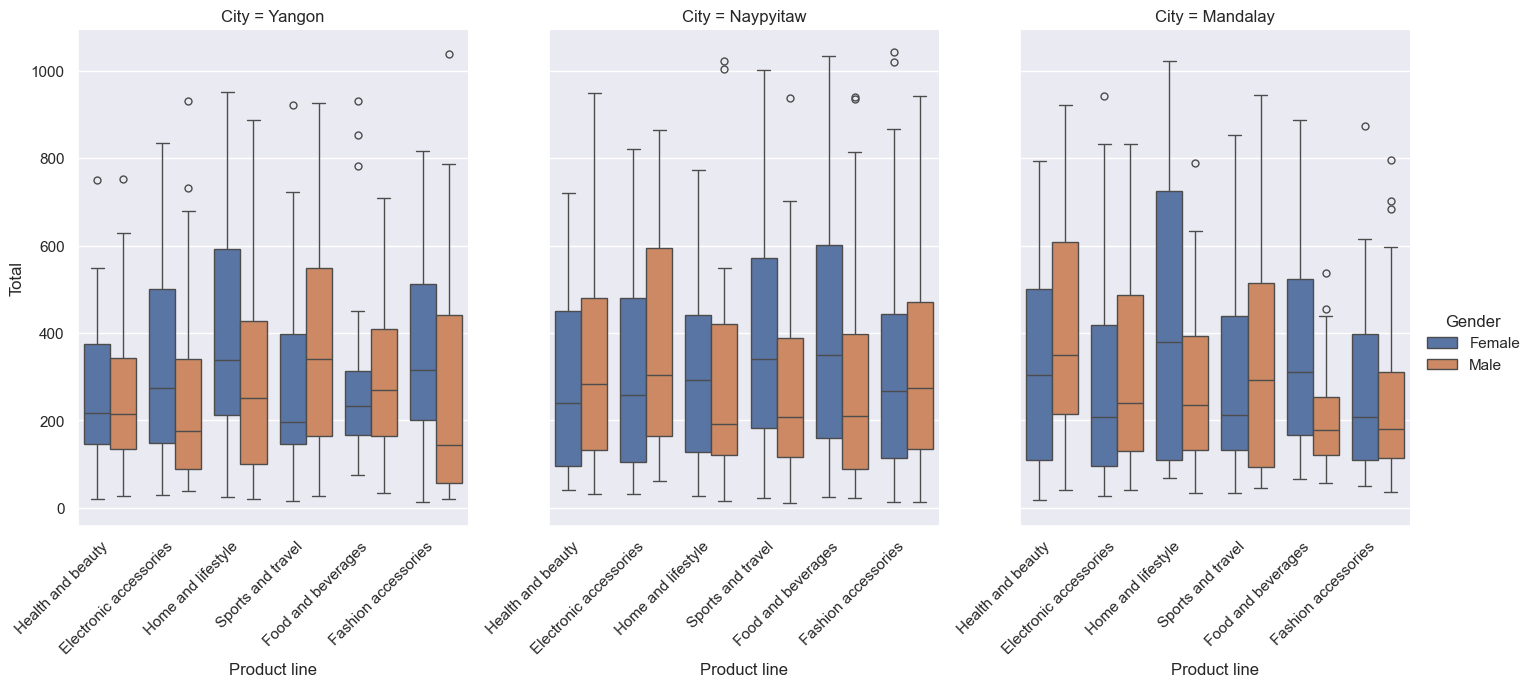

In [58]:
chart = sns.catplot(x="Product line",
                    y="Total",
                    hue="Gender",
                    col="City",
                    kind="box",
                    data=market_df,
                    height=6,
                    aspect=.8)
chart.set_xticklabels(rotation=45, ha="right");

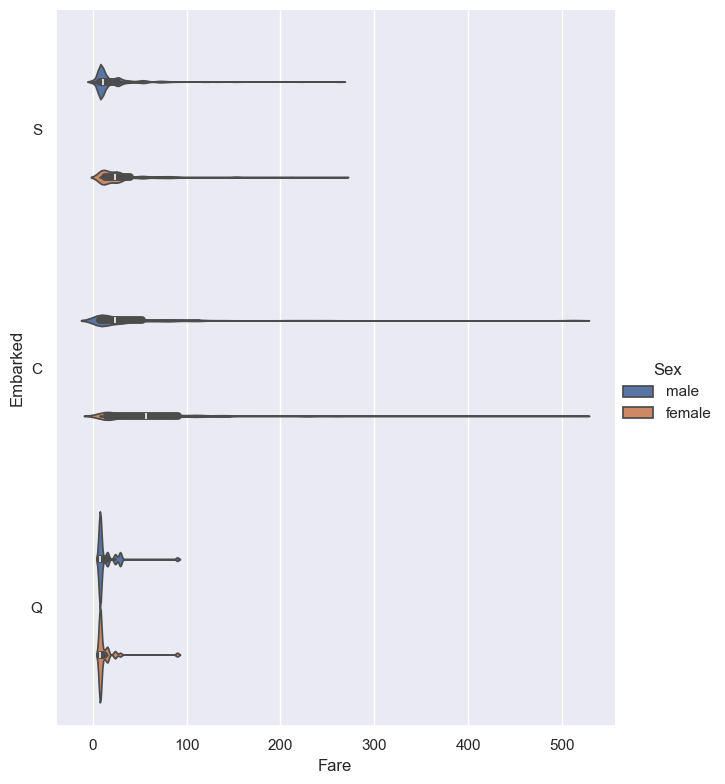

In [59]:
sns.catplot(x="Fare",
            y="Embarked",
            hue="Sex",
            kind="violin",
            bw_method=.1,
            height=8,
            aspect=.8,
            data=titanic_df);

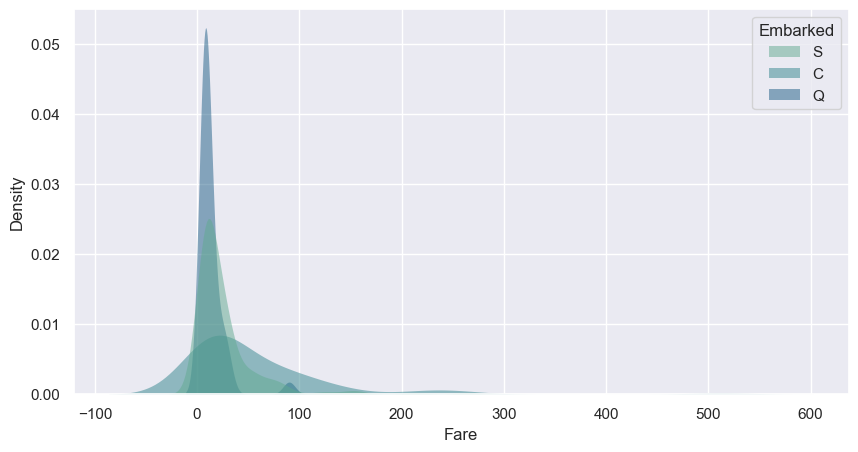

In [60]:
plt.figure(figsize=(10,5))
sns.kdeplot(data=titanic_df, x="Fare", hue="Embarked",
            fill=True, common_norm=False, palette="crest",
            alpha=.5, linewidth=0);

#### Diagramas de barras

Número de festivos y eventos por año:

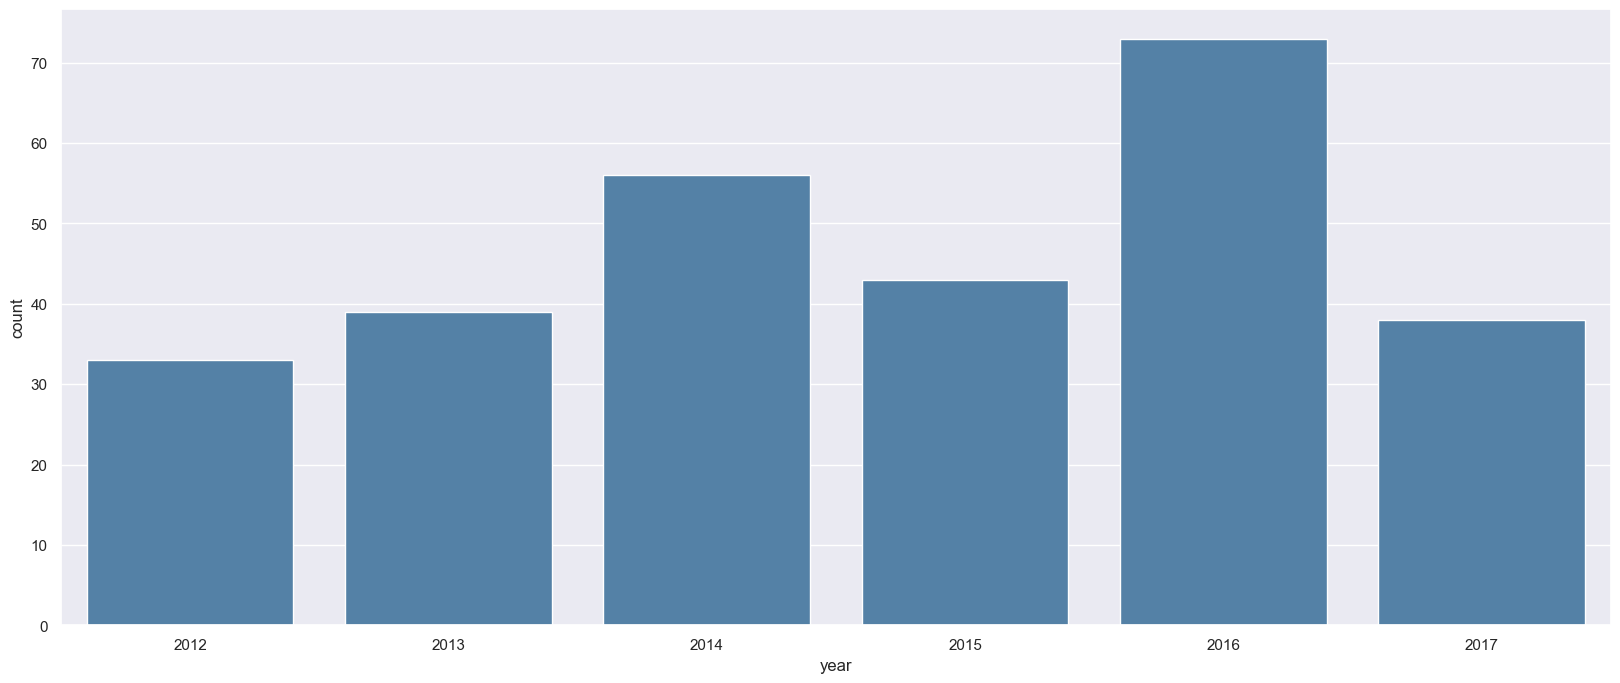

In [61]:
plt.figure(figsize=(20,8))
sns.countplot(x="year",
              data=eventos_df,
              color="steelblue");

Y superponiendo dos barras podemos comparar el total con una parte de él, en este caso los festivos de ámbito local:

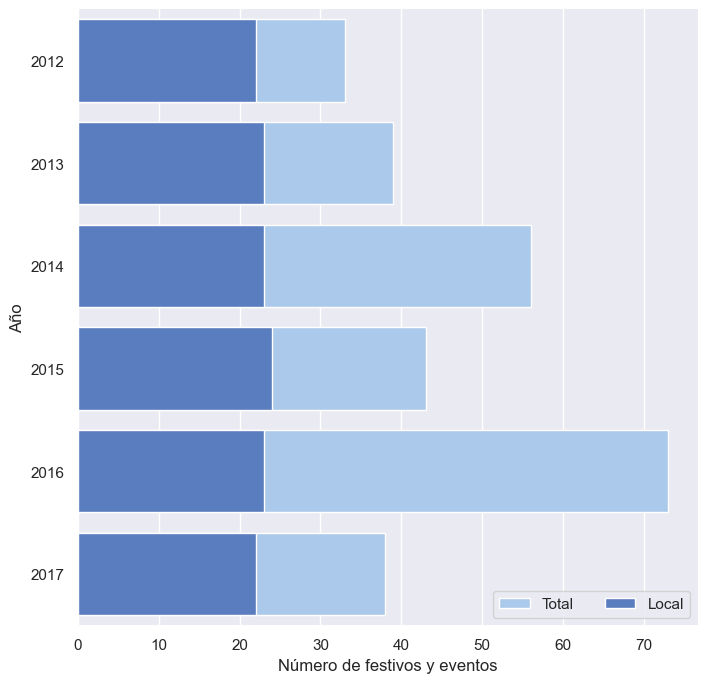

In [62]:
total = eventos_df.groupby("year").size()
local = eventos_df[eventos_df["locale"] == "Local"].groupby("year").size()
df_tot = pd.DataFrame({"Total": total, "Local": local}).fillna(0).reset_index()
df_tot["year"] = df_tot["year"].astype(str)

f, ax = plt.subplots(figsize=(8, 8))

sns.set_color_codes("pastel")
sns.barplot(x="Total", y="year", data=df_tot,
            label="Total", color="b")

sns.set_color_codes("muted")
sns.barplot(x="Local", y="year", data=df_tot,
            label="Local", color="b")

# Leyenda y etiquetas de los ejes
ax.legend(ncol=2, loc="lower right", frameon=True)
ax.set(xlabel="Número de festivos y eventos", ylabel="Año")
sns.despine(left=True, bottom=True)

#### Bubble chart

Un gráfico de dispersión en el que el tamaño de los puntos codifica una tercera variable numérica (y el color, una cuarta). Con el dataset de California housing, situando cada zona por su longitud y latitud, con el tamaño según su población y el color según el valor mediano de la vivienda, obtenemos casi un mapa:

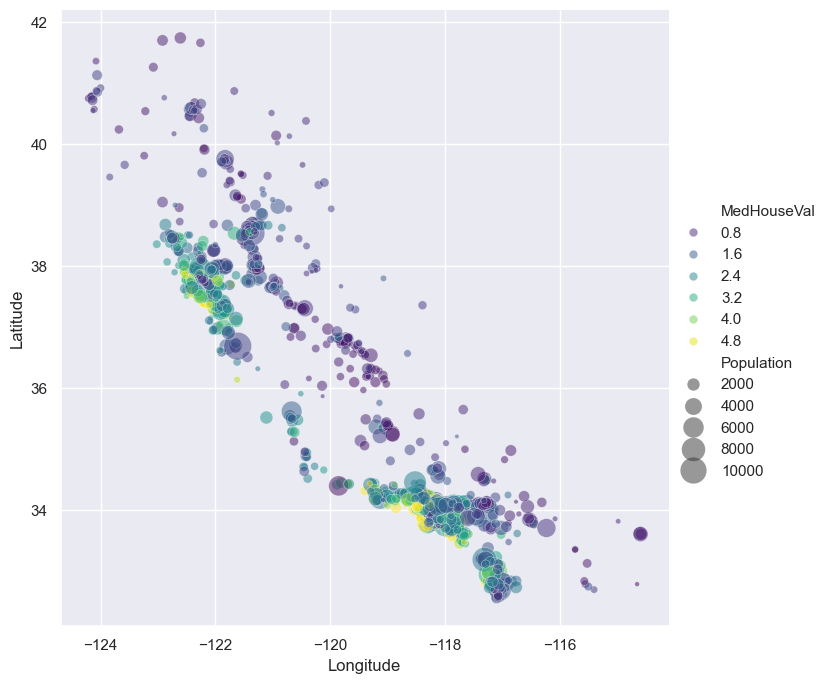

In [63]:
sns.relplot(data=california_df.sample(1500, random_state=42),
            x="Longitude",
            y="Latitude",
            hue="MedHouseVal", size="Population",
            sizes=(10, 400),
            alpha=.5, palette="viridis",
            height=7);